# Preprocessing and exploratory analysis

Plan deliverable **2.7**.

## What this notebook is, and is not

This notebook **imports** the project's modules and renders their output. It
does not reimplement anything, and **no number reported anywhere in this
project originates in a notebook cell**.

That is deliberate. The project plan asks for a preprocessing notebook;
`CLAUDE.md` rule 3.9 requires that every reported result come from a
config-driven script, so that it can be reproduced by a command rather than
by executing cells in the right order. Those two requirements are satisfied
together by keeping the scripts as the single source of truth and using the
notebook as a readable view over them.

If a figure here disagrees with one in `results/`, the file in `results/` is
correct and this notebook needs re-running.

| Section | Module it calls |
|---|---|
| 1. Dataset overview | `src/dataset_stats.py` |
| 2. Class distribution | `src/dataset_stats.py` |
| 3. Missing values | `src/dataset_stats.py`, `src/preprocess.py` |
| 4. Duplicates and the accuracy ceiling | `src/dataset_stats.py` |
| 5. The two split protocols | `src/split.py` |
| 6. Train-only preprocessing | `src/preprocess.py` |

In [1]:
import os
import sys
from pathlib import Path

# Run from the repository root, whatever directory Jupyter started in, so
# that every relative path below matches the one the scripts use.
ROOT = Path.cwd()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 50)
print('repository root:', ROOT)

repository root: D:\Projects\IoT ML Intrusion Detection


## 1. Dataset overview

These tables are produced by `src/dataset_stats.py`. Re-generate them with:

```
python src/dataset_stats.py
```

In [2]:
overall = pd.read_csv('results/tables/dataset_stats_overall.csv', index_col=0)
overall

,value
corpus_rows,46776700.00
corpus_capture_files,309.00
feature_columns,39.00
independent_feature_signals,36.00
raw_labels,34.00
categories,8.00
subsample_rows,4458051.00
subsample_cap_per_class,200000.00
subsample_pct_of_corpus,9.53
imbalance_ratio_corpus,2601.40


## 2. Class distribution

The rightmost column, `n_files_full`, is the one that constrains the whole
method. Under Protocol B the split is made on the capture file, so this is the
number of indivisible units each class has. **Brute Force has one**, which
means it cannot be placed in training and test at the same time under any
grouped scheme.

In [3]:
by_cat = pd.read_csv('results/tables/dataset_stats_by_category.csv', index_col=0)
by_cat

,n_subtypes,rows_full,rows_sub,n_files_full,pct_corpus,pct_subsample,imbalance_vs_smallest
category,,,,,,,
DDoS,12,33984450,2052216,176,72.653,46.034,2601.4
DoS,4,7845120,671861,38,16.771,15.071,600.5
Mirai,3,2634054,600000,76,5.631,13.459,201.6
Benign,1,1098191,200000,4,2.348,4.486,84.1
Reconnaissance,5,690534,517183,5,1.476,11.601,52.9
Spoofing,2,486458,378898,3,1.040,8.499,37.2
Web-based,6,24829,24829,6,0.053,0.557,1.9
Brute Force,1,13064,13064,1,0.028,0.293,1.0


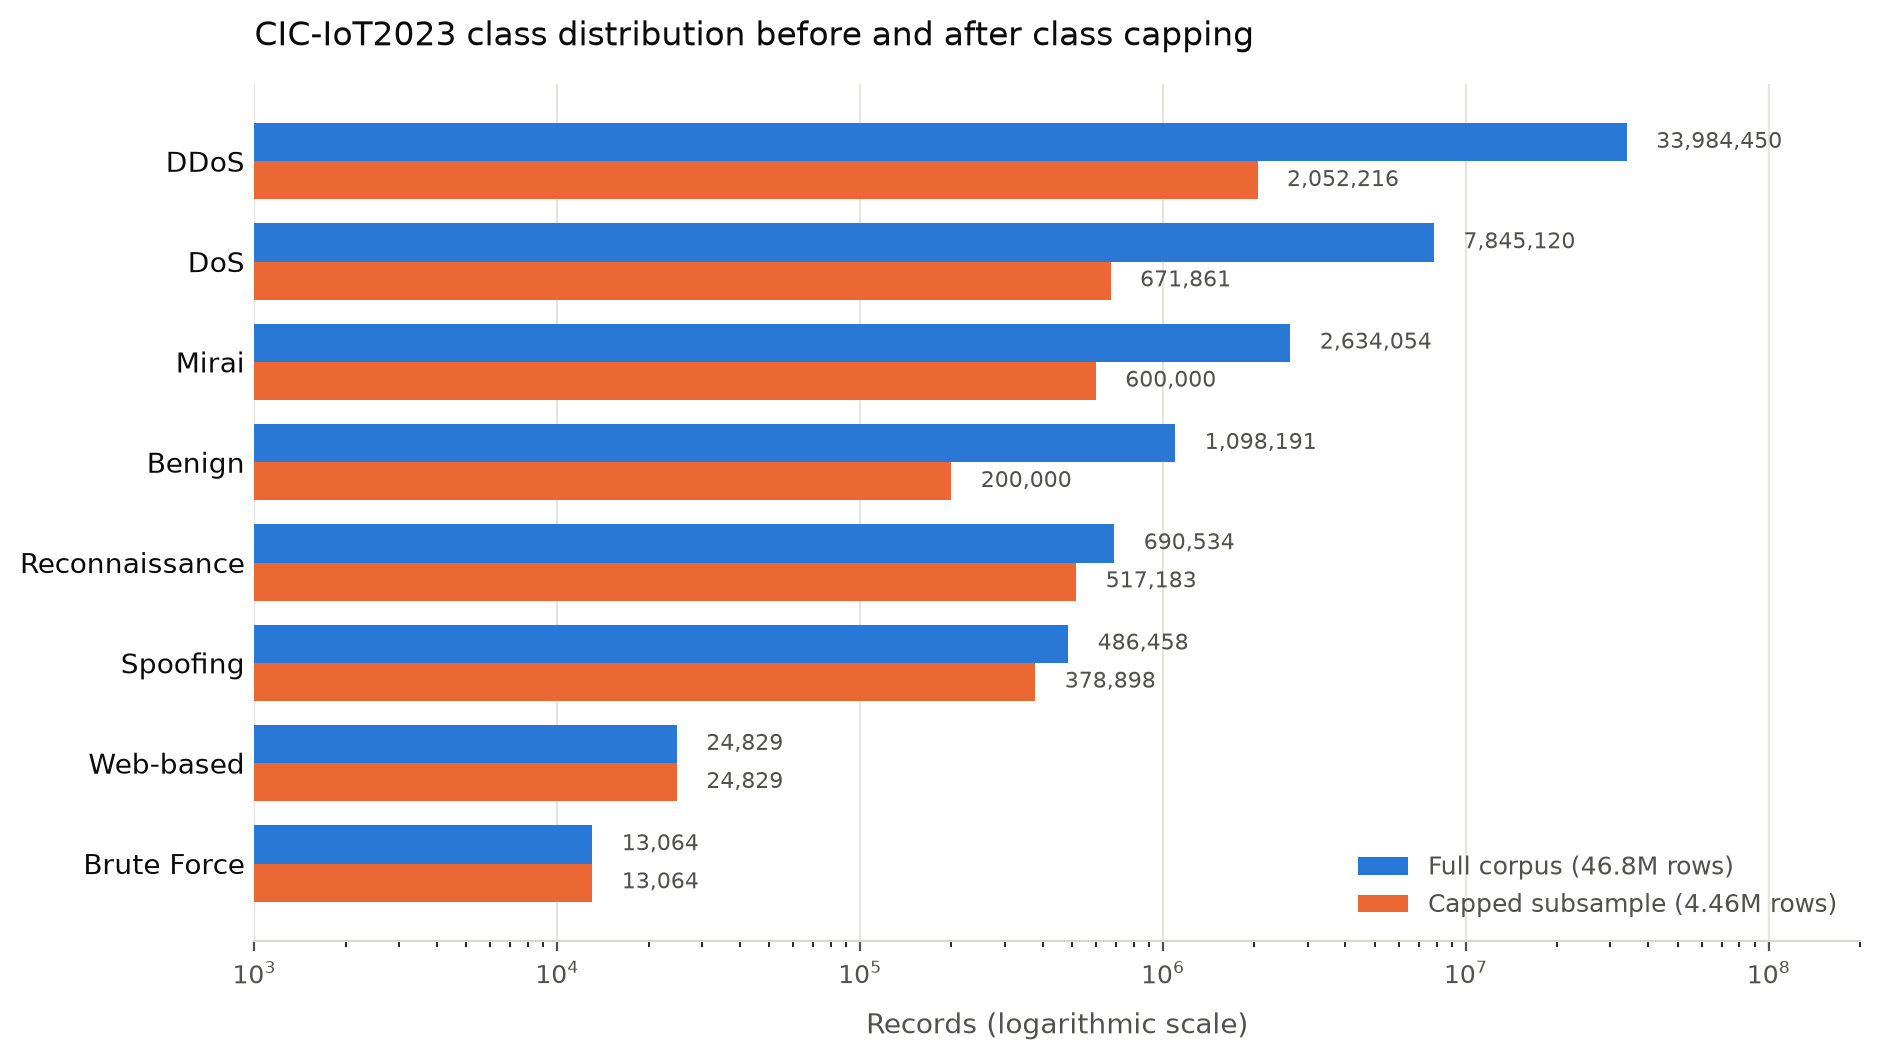

In [4]:
from IPython.display import Image, display

# Figure produced by src/dataset_stats.py -- logarithmic axis, because the
# largest class exceeds the smallest by a factor of 2,601.
display(Image(filename='results/figures/class_distribution.png', width=900))

## 3. Missing values

195 records in the working subsample carry a non-finite value, in exactly
three columns. The explanation is that they are single-packet capture windows:
with one packet in the window, standard deviation and variance are undefined
and rate divides by a zero duration.

They are removed **per partition, after the split** — never before it, because
cleaning the whole dataset first is a transform fitted on data that includes
the test partition.

In [5]:
import dataset_stats

n_bad, n_cols = dataset_stats.nonfinite_rows(dataset_stats.SUB)
print(f'rows with a non-finite feature value: {n_bad}')
print(f'columns affected:                     {n_cols}')

rows with a non-finite feature value: 195
columns affected:                     3


## 4. Duplicates and the accuracy ceiling

The important distinction here is between two quantities that are easy to
confuse:

- **Records inside a label-conflicting group.** Identical feature vectors that
  appear with more than one label somewhere in the data.
- **Irreducible (Bayes) error.** Within such a group, the best possible
  classifier predicts that group's *majority* label and is correct for every
  majority record. Only the minority records are necessarily wrong.

Using the first figure in place of the second understates the achievable
ceiling as 87.64 % rather than 96.21 %. An early version of
`dataset_stats.py` made exactly that mistake.

In [6]:
dup = {k.replace('dup_', ''): v for k, v in overall['value'].items()
       if k.startswith('dup_') or k == 'max_achievable_accuracy_pct'}
pd.Series(dup, name='working subsample').to_frame()

,working subsample
n_bayes_error_rows,169052.00
pct_bayes_error,3.79
n_rows,4458051.00
n_distinct_vectors,3570632.00
n_duplicated_rows,1086872.00
pct_duplicated_rows,24.38
n_conflicting_groups,64459.00
n_rows_in_conflicting_groups,551189.00
pct_rows_in_conflicting_groups,12.36
max_achievable_accuracy_pct,96.21


Those figures are for the **class-capped working subsample**. The corpus-level
figures are computed separately by `src/duplicates_full.py`, because capping
each subtype at 200,000 records removes a large share of the duplicate-heavy
DDoS traffic and therefore changes the rate substantially. Both scopes must be
reported with their scope stated.

In [7]:
full_path = Path('results/tables/duplicates_full_corpus.csv')
if full_path.exists():
    display(pd.read_csv(full_path, index_col=0))
else:
    print('not yet computed -- run: python src/duplicates_full.py')

,value
scope,full corpus
n_rows,46776700
n_distinct_vectors,20689442
n_duplicated_rows,28155847
pct_duplicated_rows,60.19
n_conflicting_groups,524401
n_rows_in_conflicting_groups,14057145
pct_rows_in_conflicting_groups,30.05
n_bayes_error_rows,3405070
pct_bayes_error,7.28


## 5. The two split protocols

This is the project's central mechanism. The same data is divided two ways:

- **Protocol A** — a stratified random split. The control condition, included
  to be criticised.
- **Protocol B** — a grouped split on `source_file`, so every record from one
  capture file lands entirely on one side.

The cell below runs both on the real subsample and reports what each produces.
Watch the class coverage: under Protocol B, classes can be missing from a
partition entirely, which is not a bug but the direct consequence of a class
owning few capture files.

In [8]:
import split

df = pd.read_parquet('data/processed/cic_iot2023_subsample.parquet')
print(f'{len(df):,} rows, {df["source_file"].nunique()} capture files')

rows = []
for protocol in ('A', 'B'):
    tr, te = split.split_dataset(df, protocol=protocol, seed=42)
    train_cats = set(df.iloc[tr]['label'])
    test_cats = set(df.iloc[te]['label'])
    rows.append({
        'protocol': protocol,
        'train rows': len(tr),
        'test rows': len(te),
        'test share': round(len(te) / (len(tr) + len(te)), 3),
        'raw labels in train': len(train_cats),
        'raw labels in test': len(test_cats),
        'absent from train': len(test_cats - train_cats),
    })
pd.DataFrame(rows)

4,458,051 rows, 309 capture files


,protocol,train rows,test rows,test share,raw labels in train,raw labels in test,absent from train
0,A,3566440,891611,0.200,34,34,0
1,B,3586036,872015,0.196,30,21,4


In [9]:
# The decisive check: does any capture file appear on BOTH sides?
for protocol in ('A', 'B'):
    tr, te = split.split_dataset(df, protocol=protocol, seed=42)
    shared = set(df.iloc[tr]['source_file']) & set(df.iloc[te]['source_file'])
    print(f'Protocol {protocol}: {len(shared):>3} capture files appear in '
          f'both partitions')

Protocol A: 309 capture files appear in both partitions


Protocol B:   0 capture files appear in both partitions


Protocol A shares almost every capture file between the two partitions;
Protocol B shares none. That single difference is what the whole study
measures, and it is worth roughly 12 to 17 points of macro-recall.

## 6. Train-only preprocessing

`CLAUDE.md` rule 3.3: every transform is fitted on the training partition
only. Fitting a scaler on the full dataset lets its mean and standard
deviation absorb information from the test partition, which is a real and
documented leakage path independent of the splitting question.

The cell below demonstrates that the fitted scaler's parameters come from the
training rows alone.

In [10]:
import preprocess

tr, te = split.split_dataset(df, protocol='B', seed=42)
X_train, X_test, y_train, y_test, class_names, scaler = preprocess.preprocess(
    df, tr, te, task='multiclass6')

print('classes:', class_names)
print(f'X_train {X_train.shape}   X_test {X_test.shape}')


X_train (before cleaning): (3586036, 41)   X_test (before cleaning): (872015, 41)
Dropping 157 rows with non-finite feature values (0.0044% of this partition)


Dropping 38 rows with non-finite feature values (0.0044% of this partition)
X_train (after cleaning):  (3585879, 41)   X_test (after cleaning):  (871977, 41)


task='multiclass6': dropping 508,417 rows outside the 6-class scope (14.2%)


task='multiclass6': dropping 116,365 rows outside the 6-class scope (13.3%)
X_train (in scope):        (3077462, 41)   X_test (in scope):        (755612, 41)


task='multiclass6'  classes=['Benign', 'Brute Force', 'DDoS', 'DoS', 'Reconnaissance', 'Spoofing']
                  train    test
Benign           143367   56621
Brute Force           0   13064
DDoS            1630394  421739
DoS              580939   90896
Reconnaissance   382795  134377
Spoofing         339967   38915
WARNING -- classes entirely absent from train: ['Brute Force']
classes: ['Benign', 'Brute Force', 'DDoS', 'DoS', 'Reconnaissance', 'Spoofing']
X_train (3077462, 39)   X_test (755612, 39)


In [11]:
# The scaler's mean must equal the TRAINING rows' mean, not the whole
# dataset's. If these two columns matched, the scaler would have been fitted
# on data it should never have seen.
feature_cols = preprocess.get_feature_columns(df)
scaled_cols = [c for c in feature_cols
               if c not in preprocess.NON_SCALED_FEATURE_COLS]

check = pd.DataFrame({
    'scaler mean': scaler.mean_[:6],
    'train rows mean': df.iloc[tr][scaled_cols[:6]].mean().to_numpy(),
    'ALL rows mean': df[scaled_cols[:6]].mean().to_numpy(),
}, index=scaled_cols[:6])
check

,scaler mean,train rows mean,ALL rows mean
Header_Length,17.044581,15.116946,15.107784
Time_To_Live,74.457434,73.315895,73.738701
Rate,21107.044495,inf,inf
fin_flag_number,0.060503,0.052127,0.051327
syn_flag_number,0.194125,0.167047,0.161581
rst_flag_number,0.073905,0.063483,0.067570


The first two columns agree and the third does not, which is the intended
behaviour. (The small residual difference between the first two comes from the
non-finite rows being dropped after the split, before the scaler is fitted.)

---

## Where the reported results actually come from

| Artifact | Produced by |
|---|---|
| `results/results.csv` | `src/train.py` |
| `results/tables/kfold_results.csv` | `src/kfold.py` |
| `results/tables/baseline_results.csv` | `src/report_tables.py` |
| `results/bench.csv` | `src/bench.py` |
| `results/figures/*.png` | `src/dataset_stats.py`, `src/methodology_figure.py`, `src/confusion_figures.py` |
| `docs/Final_Report_*.docx` | `docs/build_final_report.py` |

Every methodological decision, including the ones that turned out to be
mistakes, is dated and recorded in `DECISIONS.md`.